<a href="https://colab.research.google.com/github/SawNyanLinTun/visionlab/blob/main/Vision_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project: Shape Recognition with a Convolutional Neural Network (CNN)

Welcome to our first step into Artificial Intelligence and Computer Vision!
Today, we are going to build a neural network from scratch using **PyTorch**.

### What we will learn today:
1. Environment Setup: Loading our AI toolkits.
2. Synthetic Data: How computers generate shapes.
3. Data Splitting: Organizing data into study material (Train), quizzes (Val), and final exams (Test).
4. The Brain (CNN): Building a Convolutional Neural Network.
5. Training: Letting the computer learn from its mistakes.
6. Evaluation: Finding out how smart our AI is!

---

##  Step 1: Loading our Tools
Before we begin, we must import our python libraries—think of these as the toolbox we need to build our machine.


In [46]:
#Import required libraries

import numpy as np
import matplotlib.pyplot as plt
import torch

from PIL import Image, ImageDraw
from torch import nn
from torch.utils.data import Dataset, DataLoader

# Make results reproducible
SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)

# Select CPU or GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)
print("Setup completed successfully!")


PyTorch version: 2.11.0+cu130
Device: cuda
Setup completed successfully!


##  Step 2: Creating and Visualizing Shapes
Let's teach our computer what a Circle, Square, and Triangle look like. First, we will create a simple function to draw these shapes on a blank digital canvas.

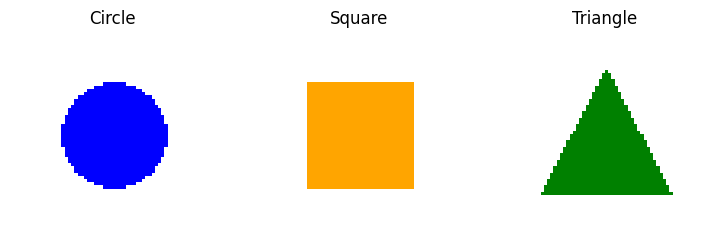

In [49]:
#Create our first images

def generate_shape(shape, size=64):
    image = Image.new("RGB",(size, size),color="white")

    draw = ImageDraw.Draw(image)

    if shape == "circle":
        draw.ellipse(
            (16, 16, 48, 48),
            fill="blue"
        )

    elif shape == "square":
        draw.rectangle(
            (16, 16, 48, 48),
            fill="orange"
        )

    elif shape == "triangle":
        draw.polygon(
            [(32, 12), (52, 50), (12, 50)],
            fill="green"
        )

    else:
        raise ValueError("Unknown shape")

    return image


classes = ["circle", "square", "triangle"]

fig, axes = plt.subplots(1, 3, figsize=(9, 3))

for ax, shape in zip(axes, classes):
    image = generate_shape(shape)

    ax.imshow(image)
    ax.set_title(shape.capitalize())
    ax.axis("off")

plt.show()


###  Inspecting the Image Pixels
How does a computer see an image? It sees a grid of numbers representing red, green, and blue pixels! Let's inspect the dimensions and values of a single sample image.

In [50]:
#Inspect Image dimensions

sample_image = generate_shape("circle")

image_array = np.array(sample_image)

print("Image shape:", image_array.shape)
print("Data type:", image_array.dtype)
print("First pixel:", image_array[0, 0])


Image shape: (64, 64, 3)
Data type: uint8
First pixel: [255 255 255]


##  Step 3: Making the Problem Challenging (Randomization)
In the real world, shapes are not always in the exact center, and colors change! Let's generate shapes with random sizes, colors, positions, and backgrounds to make our model robust.


In [52]:
#Create Randomized shapes

import random

def generate_random_shape(shape, size=64):
    image = Image.new(
        "RGB",
        (size, size),
        color=tuple(random.randint(180, 255) for _ in range(3))
    )

    draw = ImageDraw.Draw(image)

    # Random foreground colour
    color = tuple(random.randint(0, 150) for _ in range(3))

    # Random position and size
    width = random.randint(20, 38)
    x = random.randint(5, size - width - 5)
    y = random.randint(5, size - width - 5)

    if shape == "circle":
        draw.ellipse(
            (x, y, x + width, y + width),
            fill=color
        )

    elif shape == "square":
        draw.rectangle(
            (x, y, x + width, y + width),
            fill=color
        )

    elif shape == "triangle":
        draw.polygon(
            [
                (x + width // 2, y),
                (x + width, y + width),
                (x, y + width)
            ],
            fill=color
        )

    else:
        raise ValueError("Unknown shape")

    return image


### Let's see some random samples!
Let's plot a few generated shapes to ensure they look diverse and correctly randomized.


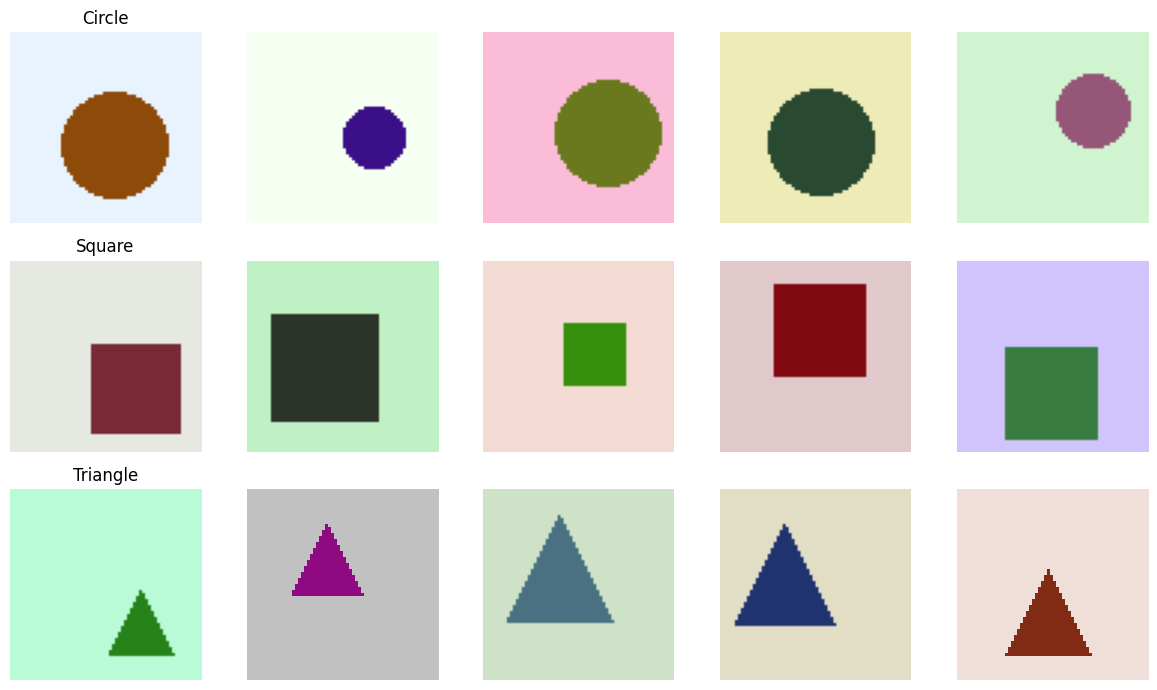

In [53]:
#Visualize randomized samples

fig, axes = plt.subplots(3, 5, figsize=(12, 7))

for row, shape in enumerate(classes):
    for col in range(5):
        image = generate_random_shape(shape)

        axes[row, col].imshow(image)
        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_title(shape.capitalize())

plt.tight_layout()
plt.show()


##  Step 4: Generating and Splitting Our Dataset
To train our model, we need to generate hundreds of shape images and divide them carefully:
* **Train (70%)**: Images the model uses to learn.
* **Validation (15%)**: Images used to test the model during training.
* **Test (15%)**: A final exam of unseen images to verify true learning.


In [54]:
#Generate and save images

import os

random.seed(42)

dataset_dir = "shape_dataset"

for shape in classes:
    folder = os.path.join(dataset_dir, shape)
    os.makedirs(folder, exist_ok=True)

    for i in range(300):
        image = generate_random_shape(shape)

        image.save(
            os.path.join(folder, f"{shape}_{i:04d}.png")
        )

print("Dataset created successfully!")

for shape in classes:
    folder = os.path.join(dataset_dir, shape)
    print(shape, ":", len(os.listdir(folder)), "images")


Dataset created successfully!
circle : 300 images
square : 300 images
triangle : 300 images


###  Running the Split
We will now run the Python code that shuffles our dataset and puts them in separate folders.


In [55]:
#Split with Python

import shutil
from pathlib import Path

split_dir = Path("shape_data_split")

# Remove old split to avoid duplicated/stale files
if split_dir.exists():
    shutil.rmtree(split_dir)

rng = random.Random(42)

for shape in classes:
    images = sorted(
        Path(dataset_dir, shape).glob("*.png")
    )

    rng.shuffle(images)

    train_images = images[:210]
    val_images = images[210:255]
    test_images = images[255:300]

    splits = {
        "train": train_images,
        "val": val_images,
        "test": test_images
    }

    for split_name, image_list in splits.items():
        output_folder = split_dir / split_name / shape
        output_folder.mkdir(parents=True, exist_ok=True)

        for image_path in image_list:
            shutil.copy2(
                image_path,
                output_folder / image_path.name
            )

for split in ["train", "val", "test"]:
    count = len(list((split_dir / split).rglob("*.png")))
    print(f"{split}: {count} images")


train: 630 images
val: 135 images
test: 135 images


## Step 5: Preparing Data for the Neural Network
Computers love matrices and tensors. We will build a **custom PyTorch Dataset** class to load our images, scale pixel values to $[0, 1]$, and prepare them in small batches (DataLoaders) for training.


In [56]:
#Create a custom Dataset class

from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
import torch

class ShapeDataset(Dataset):
    def __init__(self, root_dir, classes):
        self.samples = []
        self.classes = classes

        for label, shape in enumerate(classes):
            folder = Path(root_dir) / shape

            for image_path in sorted(folder.glob("*.png")):
                self.samples.append((image_path, label))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_path, label = self.samples[index]

        image = Image.open(image_path).convert("RGB")

        # Convert pixel values from 0-255 to 0-1
        image_array = np.asarray(
            image, dtype=np.float32
        ) / 255.0

        # PyTorch expects channels first: (3, 64, 64)
        image_array = image_array.transpose(2, 0, 1).copy()

        image_tensor = torch.from_numpy(image_array)

        return image_tensor, torch.tensor(label, dtype=torch.long)


train_dataset = ShapeDataset("shape_data_split/train", classes)
val_dataset = ShapeDataset("shape_data_split/val", classes)
test_dataset = ShapeDataset("shape_data_split/test", classes)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

images, labels = next(iter(train_loader))

print("Batch images shape:", images.shape)
print("Batch labels shape:", labels.shape)


Training samples: 630
Validation samples: 135
Testing samples: 135
Batch images shape: torch.Size([32, 3, 64, 64])
Batch labels shape: torch.Size([32])


##  Step 6: Building the Convolutional Neural Network (CNN)
A **CNN** is a special type of neural network that mimics how the human visual cortex detects edges, textures, and shapes!
* **Features**: Convolutional layers extract visual attributes.
* **Classifier**: Linear layers decide whether the shape is a circle, square, or triangle.


In [57]:
#Build the network

import torch.nn as nn

class ShapeCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 16 * 16, 64),
            nn.ReLU(),
            nn.Linear(64, 3)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = ShapeCNN().to(device)

print(model)

total_params = sum(
    p.numel() for p in model.parameters()
)

print(f"\nTotal parameters: {total_params:,}")


ShapeCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=8192, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=3, bias=True)
  )
)

Total parameters: 529,635


## Step 7: Setting Up the Training Rules (Optimizer & Loss)
* **Loss Function (CrossEntropyLoss)**: Measures how wrong the AI's guesses are.
* **Optimizer (Adam)**: The learning algorithm that adjusts parameters to minimize mistakes.
* **Epochs**: The number of times the AI reviews the complete study guide.


In [58]:
#Train configuration

import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 15

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

print("Training configuration ready!")


Training configuration ready!


## Step 8: The Training Loop!
Let's start the training process. Watch the **Train Acc** (Accuracy) and **Val Acc** go up as the model repeatedly practices!


In [59]:
#Training loop

import copy

best_val_accuracy = -1.0
best_model_state = None

for epoch in range(EPOCHS):

    # TRAINING
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * labels.size(0)
        train_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()

        train_total += labels.size(0)

    epoch_train_loss = train_loss / train_total
    epoch_train_acc = train_correct / train_total

    # VALIDATION
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)
            val_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()

            val_total += labels.size(0)

    epoch_val_loss = val_loss / val_total
    epoch_val_acc = val_correct / val_total

    history["train_loss"].append(epoch_train_loss)
    history["train_accuracy"].append(epoch_train_acc)
    history["val_loss"].append(epoch_val_loss)
    history["val_accuracy"].append(epoch_val_acc)

    # Keep best validation checkpoint
    if epoch_val_acc > best_val_accuracy:
        best_val_accuracy = epoch_val_acc
        best_model_state = copy.deepcopy(model.state_dict())

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Acc: {epoch_train_acc:.2%} | "
        f"Val Acc: {epoch_val_acc:.2%} | "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Val Loss: {epoch_val_loss:.4f}"
    )

# Restore the best validation model
model.load_state_dict(best_model_state)
model.eval()

print("\nTraining complete!")
print(f"Best validation accuracy: {best_val_accuracy:.2%}")


Epoch 01/15 | Train Acc: 31.59% | Val Acc: 46.67% | Train Loss: 1.1042 | Val Loss: 1.0843
Epoch 02/15 | Train Acc: 52.86% | Val Acc: 40.74% | Train Loss: 1.0439 | Val Loss: 1.0288
Epoch 03/15 | Train Acc: 60.95% | Val Acc: 62.96% | Train Loss: 0.8968 | Val Loss: 0.7862
Epoch 04/15 | Train Acc: 70.00% | Val Acc: 63.70% | Train Loss: 0.7006 | Val Loss: 0.7304
Epoch 05/15 | Train Acc: 75.40% | Val Acc: 70.37% | Train Loss: 0.5660 | Val Loss: 0.7021
Epoch 06/15 | Train Acc: 80.32% | Val Acc: 75.56% | Train Loss: 0.4834 | Val Loss: 0.5517
Epoch 07/15 | Train Acc: 82.70% | Val Acc: 75.56% | Train Loss: 0.4295 | Val Loss: 0.5051
Epoch 08/15 | Train Acc: 87.14% | Val Acc: 74.81% | Train Loss: 0.3357 | Val Loss: 0.5019
Epoch 09/15 | Train Acc: 89.21% | Val Acc: 81.48% | Train Loss: 0.3051 | Val Loss: 0.4175
Epoch 10/15 | Train Acc: 91.27% | Val Acc: 86.67% | Train Loss: 0.2455 | Val Loss: 0.3504
Epoch 11/15 | Train Acc: 94.60% | Val Acc: 91.85% | Train Loss: 0.1792 | Val Loss: 0.2678
Epoch 12/1

### Plotting our Learning Curve
Let's visualize the training progress. We want to see accuracy rise and loss fall for both training and validation sets!


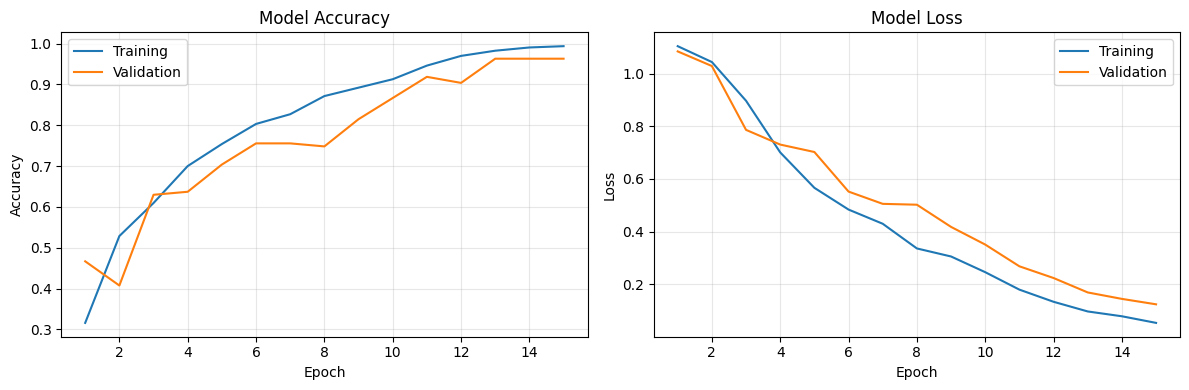

In [60]:
#Visualize training results

import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    epochs,
    history["train_accuracy"],
    label="Training"
)
axes[0].plot(
    epochs,
    history["val_accuracy"],
    label="Validation"
)
axes[0].set_title("Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    epochs,
    history["train_loss"],
    label="Training"
)
axes[1].plot(
    epochs,
    history["val_loss"],
    label="Validation"
)
axes[1].set_title("Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Step 9: Saving the Model
Once we have a trained brain, we don't want to lose it! Let's save our neural network's weights to a file so we can reuse it anytime.


In [36]:
#Save our trained model

import pandas as pd
from pathlib import Path

Path("models").mkdir(exist_ok=True)

torch.save(
    {
        "model_state": model.state_dict(),
        "classes": classes,
        "architecture": "ShapeCNN",
        "image_size": 64
    },
    "models/m4_shapes_cnn.pt"
)

history_df = pd.DataFrame(history)
history_df.insert(
    0,
    "epoch",
    range(1, len(history_df) + 1)
)

history_df.to_csv(
    "models/m4_training_history.csv",
    index=False
)

print("Model saved: models/m4_shapes_cnn.pt")
print("History saved: models/m4_training_history.csv")


Model saved: models/m4_shapes_cnn.pt
History saved: models/m4_training_history.csv


## Step 10: Final Exam (Testing phase)
Now, we present the model with the 135 completely new images it has never seen before. Let's find out its true accuracy!


In [61]:
#Calculate test accuracy

model.eval()

test_correct = 0
test_total = 0
test_loss = 0.0

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        predictions = outputs.argmax(dim=1)

        test_correct += (
            predictions == labels
        ).sum().item()

        test_total += labels.size(0)
        test_loss += loss.item() * labels.size(0)

        all_predictions.extend(
            predictions.cpu().numpy().tolist()
        )
        all_labels.extend(
            labels.cpu().numpy().tolist()
        )

test_accuracy = test_correct / test_total
average_test_loss = test_loss / test_total

print(f"Test samples: {test_total}")
print(f"Correct predictions: {test_correct}")
print(f"Test accuracy: {test_accuracy:.2%}")
print(f"Average test loss: {average_test_loss:.4f}")


Test samples: 135
Correct predictions: 130
Test accuracy: 96.30%
Average test loss: 0.1412


### The Confusion Matrix
A confusion matrix shows where our model is getting confused. It compares the actual classes to what our model predicted.


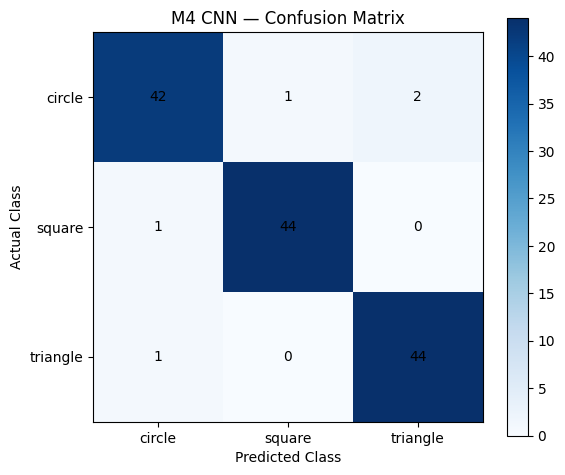

In [62]:
#Confusion matrix

import numpy as np
import matplotlib.pyplot as plt

confusion_matrix = np.zeros(
    (len(classes), len(classes)),
    dtype=int
)

for actual, predicted in zip(all_labels, all_predictions):
    confusion_matrix[actual, predicted] += 1

fig, ax = plt.subplots(figsize=(6, 5))

image = ax.imshow(
    confusion_matrix,
    cmap="Blues"
)

ax.set_xticks(range(len(classes)), classes)
ax.set_yticks(range(len(classes)), classes)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")
ax.set_title("M4 CNN — Confusion Matrix")

for i in range(len(classes)):
    for j in range(len(classes)):
        ax.text(
            j, i,
            confusion_matrix[i, j],
            ha="center",
            va="center"
        )

fig.colorbar(image)
plt.tight_layout()
plt.show()


### Detailed Classification Report
Let's calculate precision (how accurate positive predictions are) and recall (how many actual shapes were successfully spotted) for each shape.


In [63]:
#Classification report

from sklearn.metrics import classification_report

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(len(classes))),
        target_names=classes,
        zero_division=0
    )
)


              precision    recall  f1-score   support

      circle       0.95      0.93      0.94        45
      square       0.98      0.98      0.98        45
    triangle       0.96      0.98      0.97        45

    accuracy                           0.96       135
   macro avg       0.96      0.96      0.96       135
weighted avg       0.96      0.96      0.96       135



### Visualizing Random Test Predictions
Let's look at some examples of the final exam questions alongside our model's answers!


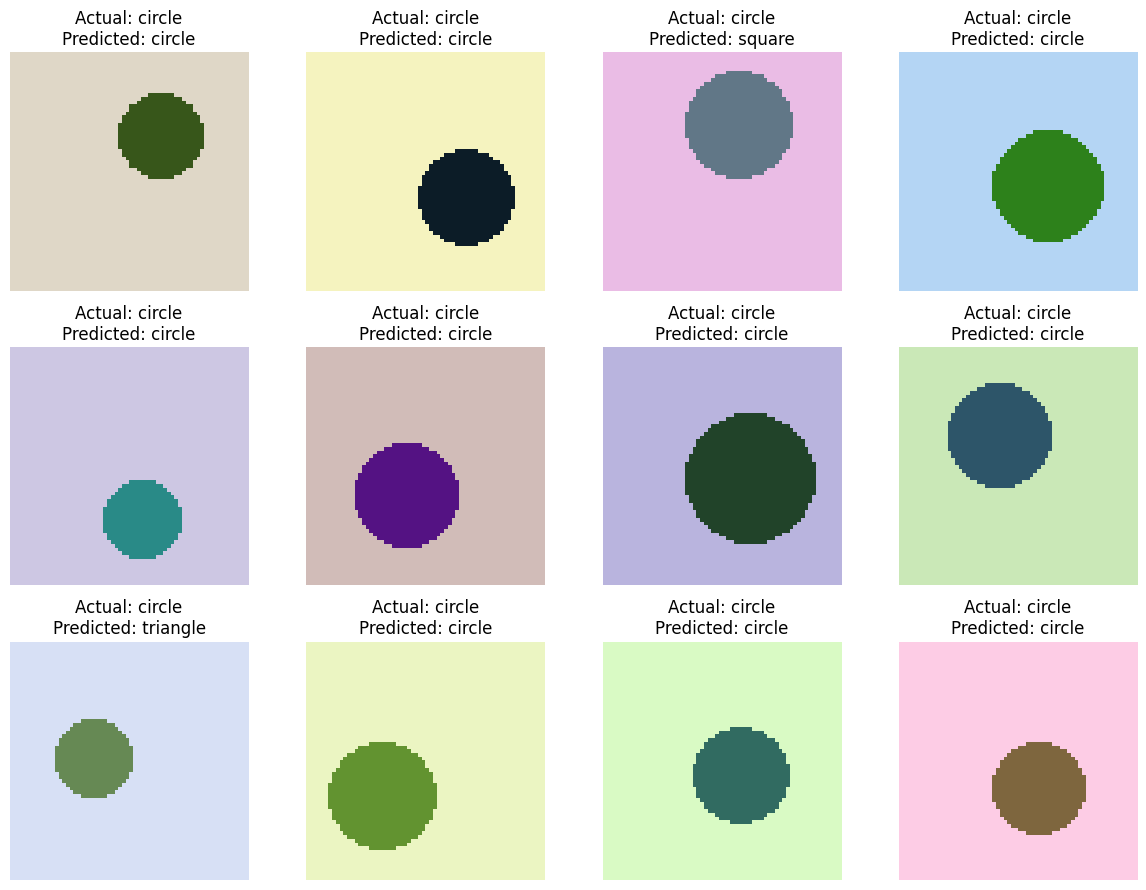

In [64]:
#Visualize individual predictions

model.eval()

images, labels = next(iter(test_loader))

with torch.no_grad():
    outputs = model(images.to(device))
    predictions = outputs.argmax(dim=1).cpu()

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for i, ax in enumerate(axes.flat):

    image = images[i].permute(1, 2, 0).numpy()

    actual = classes[labels[i].item()]
    predicted = classes[predictions[i].item()]

    ax.imshow(image)
    ax.set_title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


### Investigating the Mistakes
No one is perfect—not even our AI! Let's check which images the model got wrong to understand why it made those mistakes.


Total incorrect predictions: 5


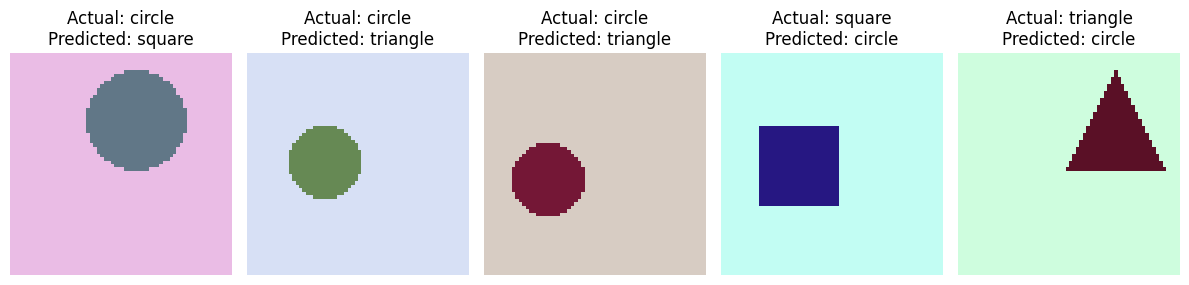

In [65]:
#Investigate misclassified images

wrong_indices = [
    i
    for i, (actual, predicted)
    in enumerate(zip(all_labels, all_predictions))
    if actual != predicted
]

print("Total incorrect predictions:", len(wrong_indices))

if wrong_indices:
    fig, axes = plt.subplots(
        1,
        min(5, len(wrong_indices)),
        figsize=(12, 3),
        squeeze=False
    )

    for ax, index in zip(axes.flat, wrong_indices[:5]):

        image_tensor, actual_label = test_dataset[index]

        image = image_tensor.permute(1, 2, 0).numpy()

        ax.imshow(image)
        ax.set_title(
            f"Actual: {classes[actual_label.item()]}\n"
            f"Predicted: {classes[all_predictions[index]]}"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No misclassified test images.")


## Step 11: Exporting Final Results
We will now write our model evaluation stats to a simple JSON file for storage and reporting.


In [66]:
#Save evaluation results

import json
from pathlib import Path

Path("models").mkdir(exist_ok=True)

metrics = {
    "model": "ShapeCNN",
    "dataset": "Synthetic Shapes",
    "classes": classes,
    "test_accuracy": float(test_accuracy),
    "test_loss": float(average_test_loss),
    "test_count": int(test_total),
    "correct_predictions": int(test_correct),
    "confusion_matrix_rows_true_cols_pred": (
        confusion_matrix.tolist()
    ),
    "best_validation_accuracy": float(best_val_accuracy)
}

with open("models/m4_test_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

print("Evaluation results saved successfully!")
print(json.dumps(metrics, indent=4))


Evaluation results saved successfully!
{
    "model": "ShapeCNN",
    "dataset": "Synthetic Shapes",
    "classes": [
        "circle",
        "square",
        "triangle"
    ],
    "test_accuracy": 0.9629629629629629,
    "test_loss": 0.14123562279122848,
    "test_count": 135,
    "correct_predictions": 130,
    "confusion_matrix_rows_true_cols_pred": [
        [
            42,
            1,
            2
        ],
        [
            1,
            44,
            0
        ],
        [
            1,
            0,
            44
        ]
    ],
    "best_validation_accuracy": 0.9629629629629629
}


## Step 12: Loading and Deploying our Model!
Imagine we are releasing our model to the public. We can load our saved file and use it to predict custom user images!


In [67]:
#Load saved model

import torch

# Create a new model instance
loaded_model = ShapeCNN().to(device)

# Load the checkpoint saved in Cell 13
checkpoint = torch.load(
    "models/m4_shapes_cnn.pt",
    map_location=device,
    weights_only=True
)

loaded_model.load_state_dict(
    checkpoint["model_state"]
)

loaded_model.eval()

print("Model loaded successfully!")
print("Classes:", checkpoint["classes"])
print("Architecture:", checkpoint["architecture"])


Model loaded successfully!
Classes: ['circle', 'square', 'triangle']
Architecture: ShapeCNN


###  Running Inference on a Single Shape
Let's make a brand new random shape and ask our loaded model to classify it.


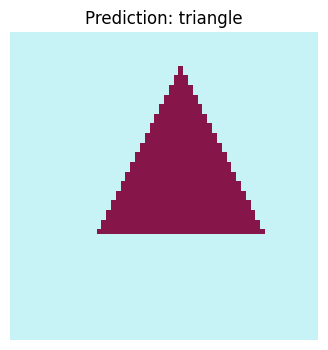

Predicted class: triangle
circle: 2.23%
square: 0.00%
triangle: 97.77%


In [68]:
#Test prediction using loaded model

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Generate a new image
new_image = generate_random_shape("triangle")

# Convert into the tensor format expected by PyTorch
image_array = np.asarray(
    new_image.resize((64, 64)).convert("RGB"),
    dtype=np.float32
) / 255.0

image_tensor = torch.from_numpy(
    image_array.transpose(2, 0, 1).copy()
).unsqueeze(0).to(device)

# Make prediction
with torch.no_grad():
    outputs = loaded_model(image_tensor)
    probabilities = torch.softmax(outputs, dim=1)[0]

predicted_index = probabilities.argmax().item()
predicted_class = classes[predicted_index]

plt.figure(figsize=(4, 4))
plt.imshow(new_image)
plt.title(f"Prediction: {predicted_class}")
plt.axis("off")
plt.show()

print("Predicted class:", predicted_class)

for name, probability in zip(classes, probabilities.cpu().tolist()):
    print(f"{name}: {probability:.2%}")


###  Multi-Image Testing
Let's run a batch prediction on multiple randomized shapes and print the results side-by-side!


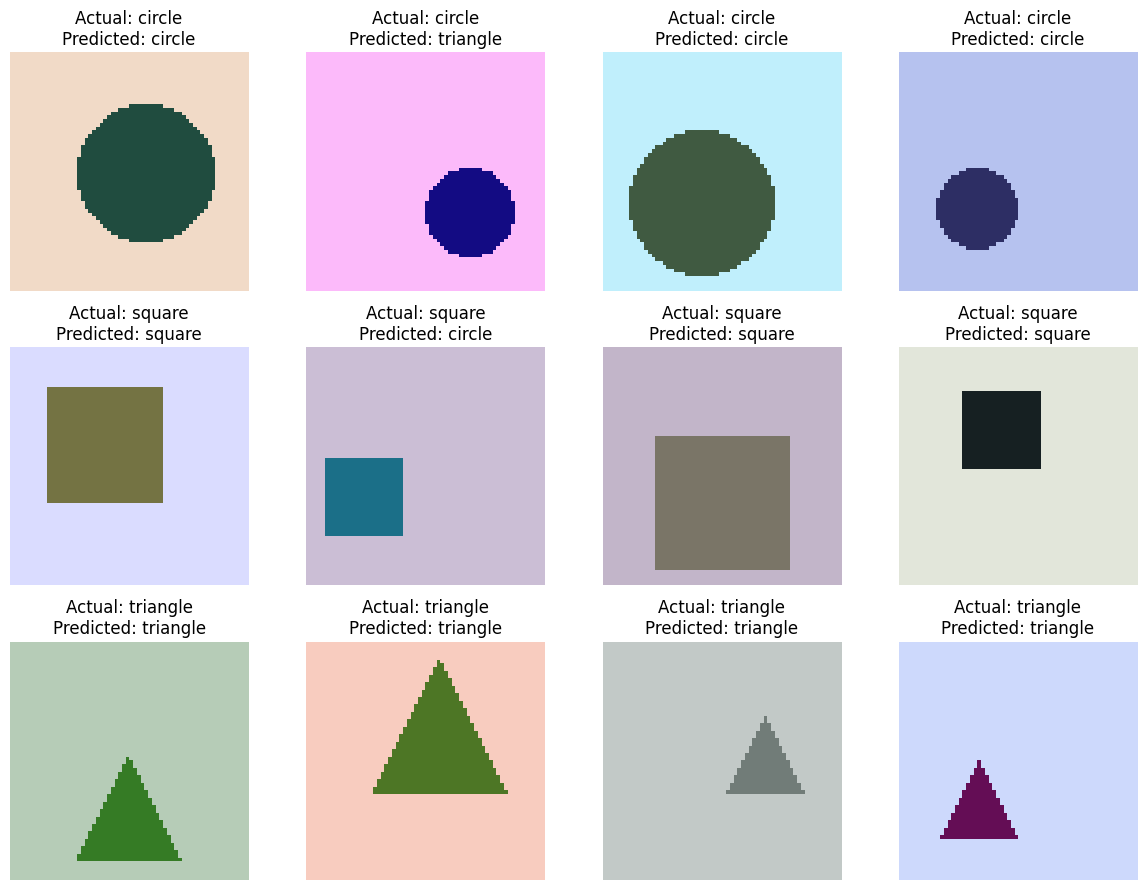

In [69]:
#Test predictions across multiple images

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

loaded_model.eval()

for row, shape in enumerate(classes):
    for col in range(4):

        image = generate_random_shape(shape)

        array = np.asarray(
            image,
            dtype=np.float32
        ) / 255.0

        tensor = torch.from_numpy(
            array.transpose(2, 0, 1).copy()
        ).unsqueeze(0).to(device)

        with torch.no_grad():
            prediction = loaded_model(tensor).argmax(dim=1).item()

        predicted_shape = classes[prediction]

        axes[row, col].imshow(image)
        axes[row, col].set_title(
            f"Actual: {shape}\nPredicted: {predicted_shape}"
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


## Step 13: Packaging Deployment Files
Finally, we zip all files together so we can download them and show off our first Computer Vision model to friends and family!


In [70]:
#Export deploy file

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

required_files = [
    Path("models/m4_shapes_cnn.pt"),
    Path("models/m4_training_history.csv"),
    Path("models/m4_test_metrics.json")
]

for path in required_files:
    if not path.is_file():
        raise FileNotFoundError(f"Missing file: {path}")

zip_name = "M4_CNN_Deployment_Files.zip"

with ZipFile(zip_name, "w", ZIP_DEFLATED) as archive:
    for path in required_files:
        archive.write(path, arcname=path.as_posix())

print("Deployment package created successfully!")

files.download(zip_name)


Deployment package created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>